# Cyberpunk 2077: Breach Protocol Solver

## Introduction

Breach Protocol is a hacking minigame in *Cyberpunk 2077* in which players must navigate a matrix of hexadecimal codes to complete predefined sequences within a limited buffer size.

As illustrated in **Figure 1**, the interface consists of three main elements:

- **Code Matrix:** A grid of hexadecimal codes from which players select symbols. Selections must alternate between rows and columns, starting from the first row.
- **Buffer:** A limited number of slots available to store the selected codes.
- **Required Sequences:** A set of target sequences associated with different rewards. Multiple sequences can be completed within a single attempt.

For simplicity, the **Code Matrix**, **Required Sequences**, and **Buffer** will hereafter be referred to as the *matrix*, *sequences*, and *buffer*, respectively.

The objective is to identify a valid path through the matrix that completes as many valuable sequences as possible without exceeding the buffer capacity.

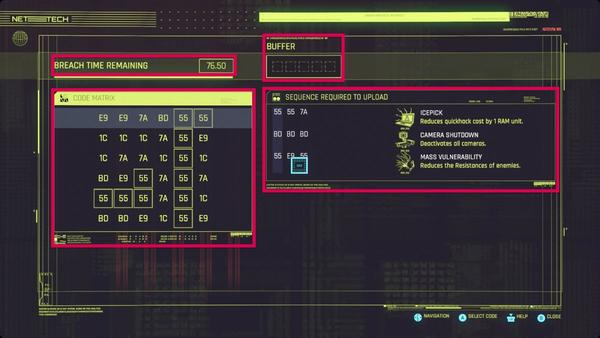

*Figure 1. Breach Protocol interface in Cyberpunk 2077, highlighting the code matrix, buffer, and required sequences.*

## Project Objective

This notebook develops a Python-based solver that automates the process, from extracting puzzle information from a photo to identifying an optimal sequence of moves.

The solution combines four computational techniques:

1. **Image Processing:** OpenCV is used to isolate relevant elements of the screenshot, while connected-component analysis and DBSCAN help identify and organize the symbols.
2. **Symbol Recognition:** Extracted symbols are normalized and classified using template matching based on Jaccard similarity.
3. **Sequence Optimization:** Target sequences are combined by identifying overlapping subsequences, aiming to maximize their value within the available buffer.
4. **Pathfinding:** A recursive depth-first search (DFS) algorithm with backtracking explores valid moves across the matrix to find a path satisfying the selected sequence.

The project demonstrates how computer vision, combinatorial optimization, and recursive algorithms can be integrated to solve a constrained problem using Python.

## 0. Setup and Configuration

Before processing the photo, the required libraries, file paths, and reference templates are initialized.

The following cells import the necessary dependencies, define the locations of the input image and template files, and load the reference symbols used during classification. A helper function is also defined to simplify image visualization throughout the notebook.

In [1]:
# Standard libraries
from itertools import permutations
from pathlib import Path

# Non-standard libraries
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from sklearn.cluster import DBSCAN

In [2]:
# Project paths
ROOT = Path.cwd()
IMAGE_PATH = ROOT / "examples" / "test_photo_2.jpeg"
TEMPLATES_PATH = ROOT / "templates"

In [3]:
# Load symbol templates
template_names = ["55", "1C", "BD", "E9", "7A", "FF"]

templates = {
    name: np.load(TEMPLATES_PATH / f"template_{name}.npy")
    for name in template_names
}

In [4]:
def show_single_img(img: np.ndarray, cmap: str | None = None) -> None:
    """
    Display an image.

    Args:
        img: Image to display.
        cmap: Matplotlib colormap (e.g., 'gray').
    """
    fig, ax = plt.subplots(figsize=(12, 8), frameon=False)
    ax.imshow(img, cmap=cmap)
    ax.axis("off")
    plt.show()

## 1. Image Processing

The objective of this stage is to isolate the two relevant regions of the screenshot: the *matrix* and the *sequences*, producing a separate image for each.

Rather than relying on fixed coordinates, the approach uses visual characteristics of the interface to locate these regions:

1. **Locate the Code Matrix header:** Identify the large, bright rectangular element labeled "CODE MATRIX", which serves as a reference point for vertically cropping the screenshot and removing irrelevant content.
2. **Extract the borders:** Apply adaptive thresholding to the cropped image to isolate the thin bright borders surrounding the relevant interface elements.
3. **Identify the regions:** Use connected-component analysis to detect the resulting shapes and select the two components corresponding to the *matrix** and *sequences*, based on their dimensions.

The result is two cropped images, which will be processed independently in the following stages to extract and classify their symbols.

### 1.1. Image Preparation

Load the input screenshot and examine its color channels to identify visual features that can help isolate the relevant interface elements. Extract the individual channels for subsequent processing, selecting those that provide the clearest distinction between the elements of interest and the background.

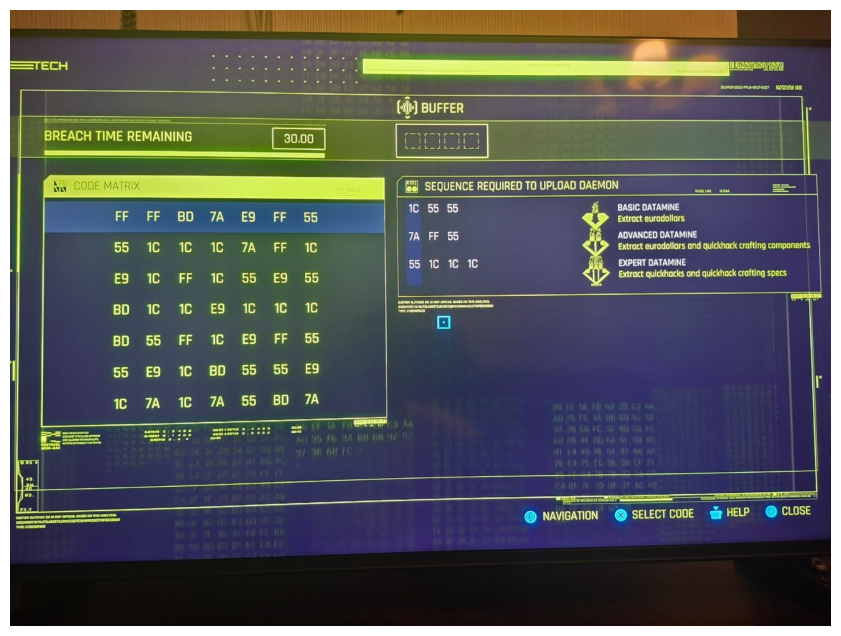

In [5]:
# Load image
img = cv.imread(str(IMAGE_PATH))

# Convert color spaces
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Display image
show_single_img(img_rgb)

In [6]:
# Extract HSV and RGB color channels
h = img_hsv[:, :, 0]
s = img_hsv[:, :, 1]
v = img_hsv[:, :, 2]

r = img_rgb[:, :, 0]
g = img_rgb[:, :, 1]
b = img_rgb[:, :, 2]

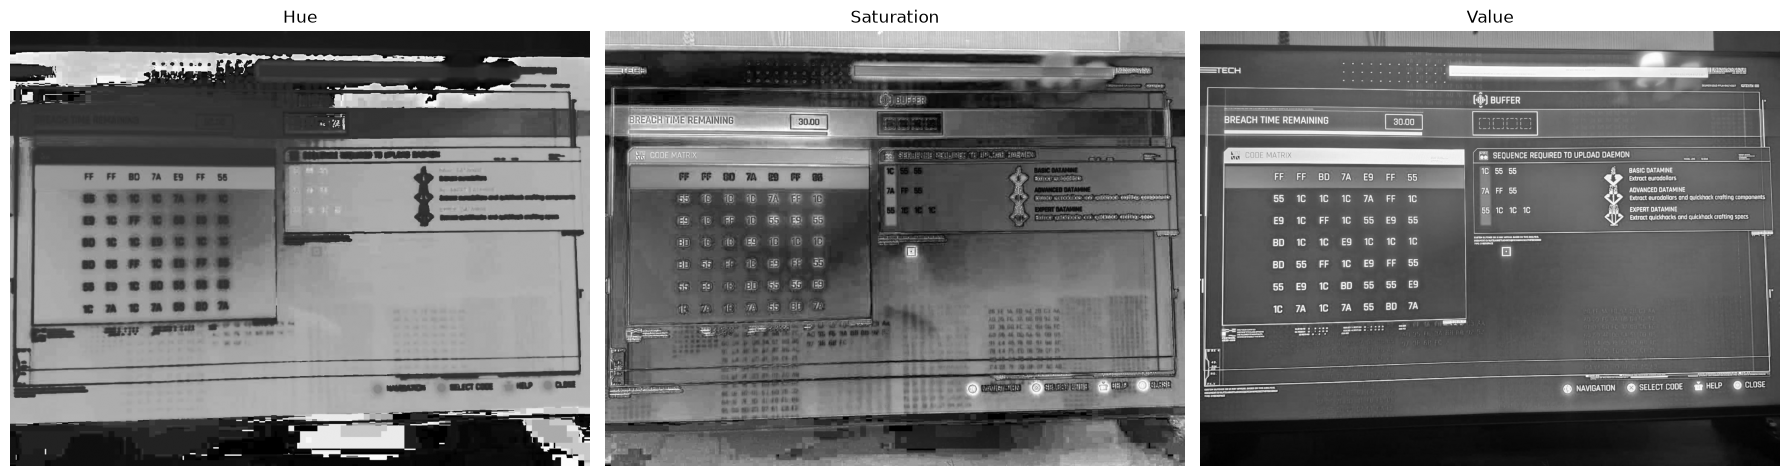

In [7]:
# Visualize HSV channels
channels = [h, s, v]
titles = ["Hue", "Saturation", "Value"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, channel, title in zip(axes, channels, titles):
    ax.imshow(channel, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

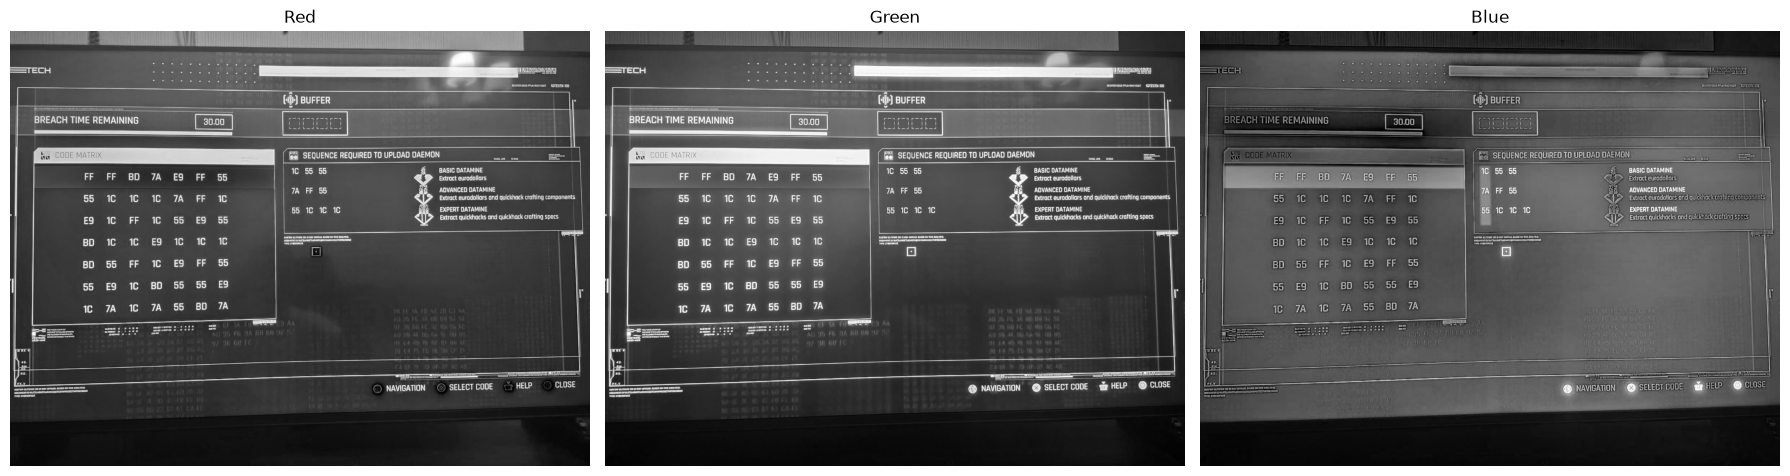

In [8]:
# Visualize RGB channels
channels = [r, g, b]
titles = ["Red", "Green", "Blue"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, channel, title in zip(axes, channels, titles):
    ax.imshow(channel, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.2. Code Matrix Header Detection

Identify the large, bright rectangular element labeled "CODE MATRIX", which serves as a reference point for vertically cropping the screenshot and removing irrelevant content.

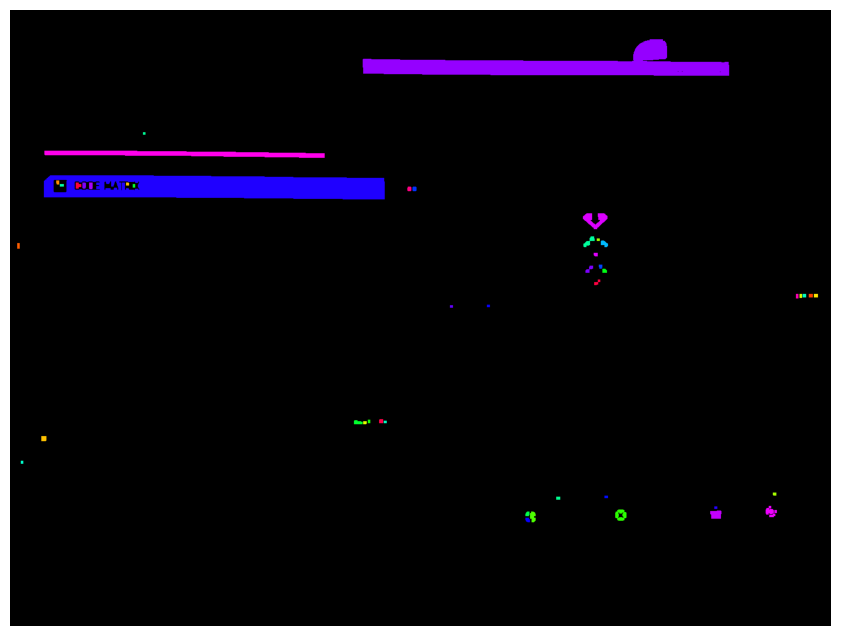

In [9]:
# Binarize the image using the HSV value channel
mask = v > 200

# Remove thin structures and noise using morphological opening
kernel = cv.getStructuringElement(cv.MORPH_RECT, (5, 5))
cleaned = cv.morphologyEx(
    mask.astype(np.uint8),
    cv.MORPH_OPEN,
    kernel
)

# Identify connected components and extract their statistics
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(cleaned, connectivity=4)

# Generate distinct colors for visualizing the components
rng = np.random.default_rng(42)
colors = plt.cm.hsv(rng.random(num_labels))
cmap = ListedColormap(colors)
cmap.set_bad("black")

# Mask the background and visualize the labeled components
labels_masked = np.ma.masked_where(labels == 0, labels)
show_single_img(labels_masked, cmap=cmap)

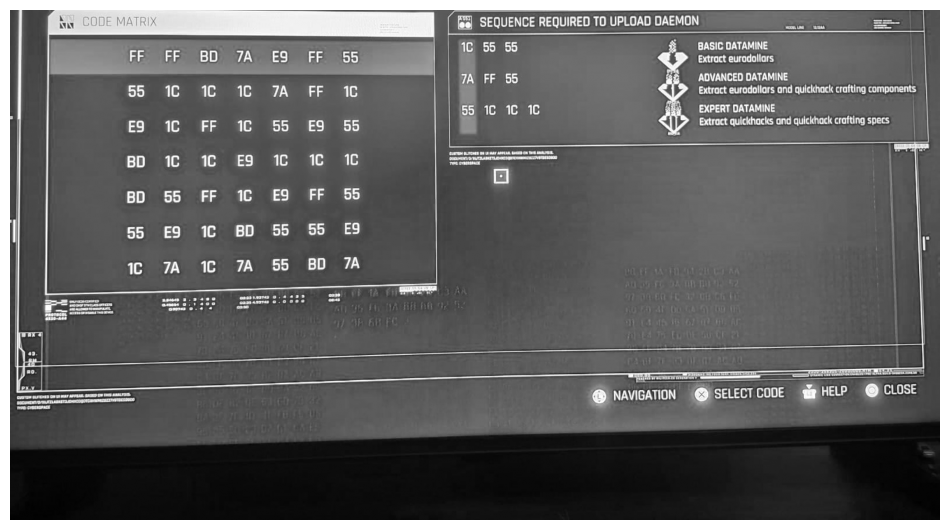

In [10]:
# Identify the three largest components by area, excluding the background
areas = stats[1:, cv.CC_STAT_AREA]
valid_components = np.argsort(areas)[-3:] + 1

# Select the lowest component among the candidates
element = valid_components[
    np.argmax(stats[valid_components, cv.CC_STAT_TOP])
]

# Crop the image from the selected component's top coordinate
start_y = stats[element, cv.CC_STAT_TOP]
cropped = v[start_y:].astype(np.uint8)
img_rgb = img_rgb[start_y:]

show_single_img(cropped, cmap='gray')

### 1.3. Border Extraction

Apply adaptive thresholding to the cropped image to isolate the bright borders surrounding the relevant interface elements.

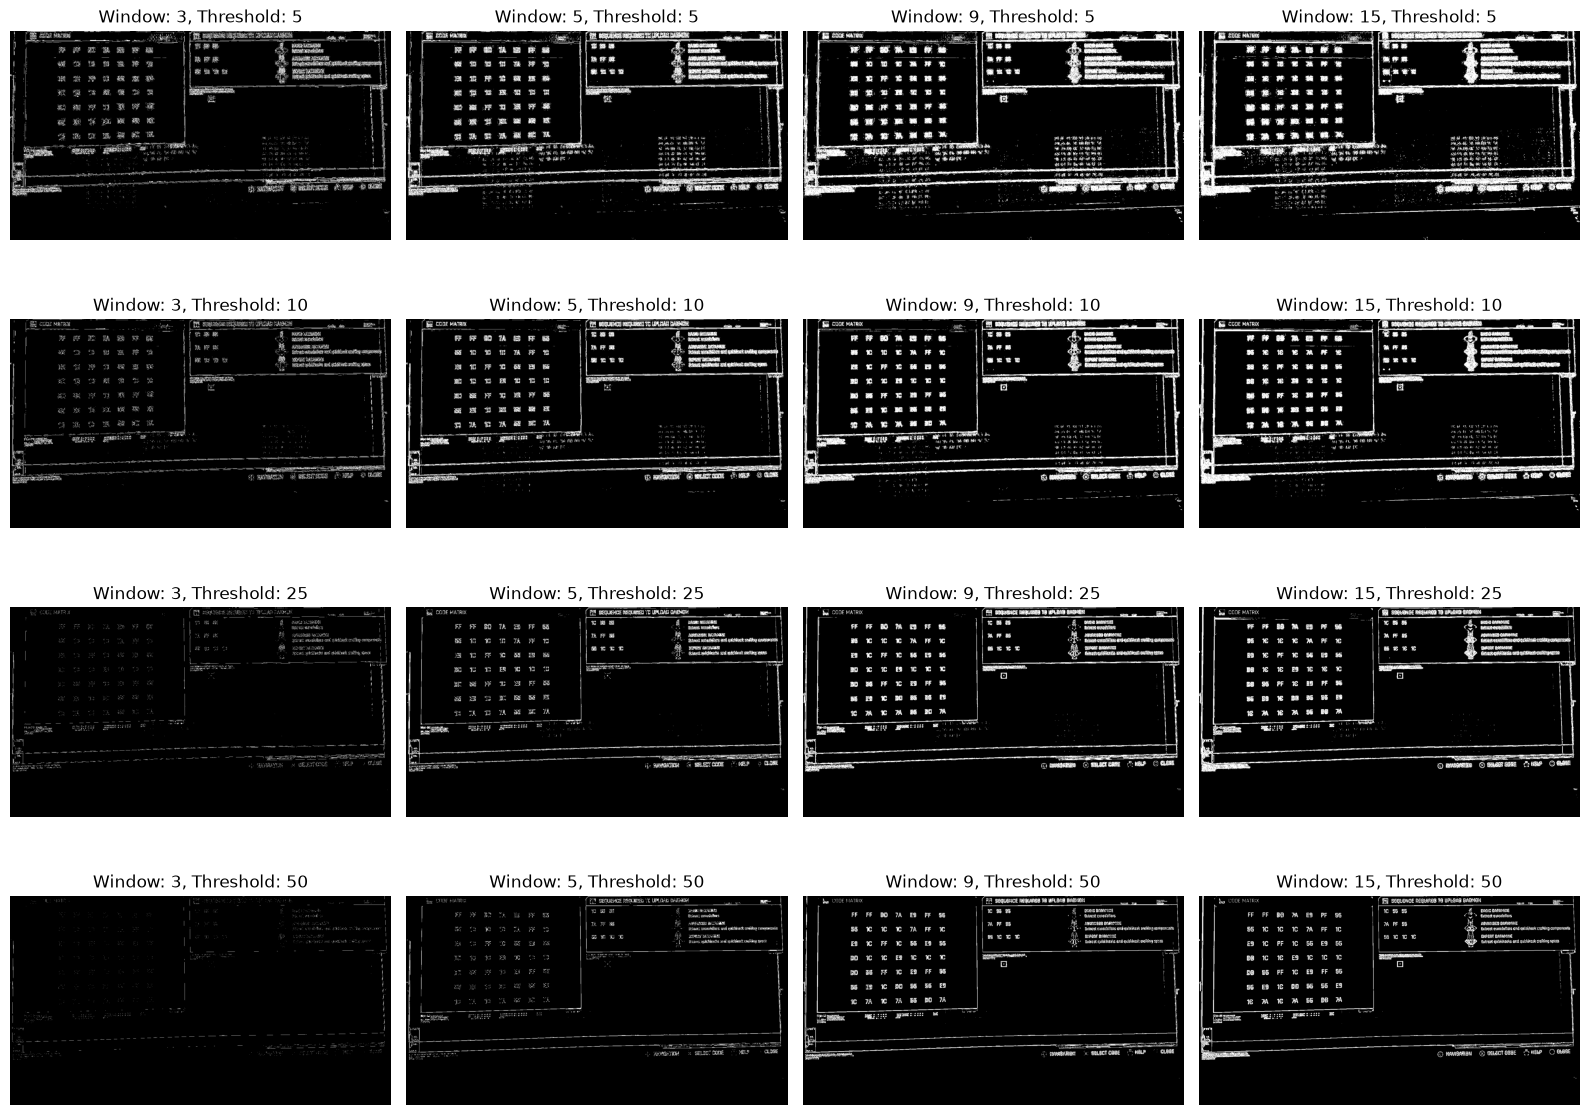

In [11]:
# Inspect binarization using local median-difference thresholding
def inspect_dynamic_thresholding(grayscale_img: np.ndarray,) -> None:
    """
    Compare median-based local thresholding parameters.
    """

    windows = [3, 5, 9, 15]
    thresholds = [5, 10, 25, 50]

    fig, axes = plt.subplots(
        len(thresholds), len(windows), figsize=(16, 12)
    )

    for j, window in enumerate(windows):
        local_median = cv.medianBlur(grayscale_img, window)
        difference = cv.absdiff(grayscale_img, local_median)

        for i, threshold in enumerate(thresholds):
            mask = difference > threshold

            ax = axes[i, j]
            ax.imshow(mask, cmap="gray")
            ax.set_title(f"Window: {window}, Threshold: {threshold}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()


inspect_dynamic_thresholding(cropped)

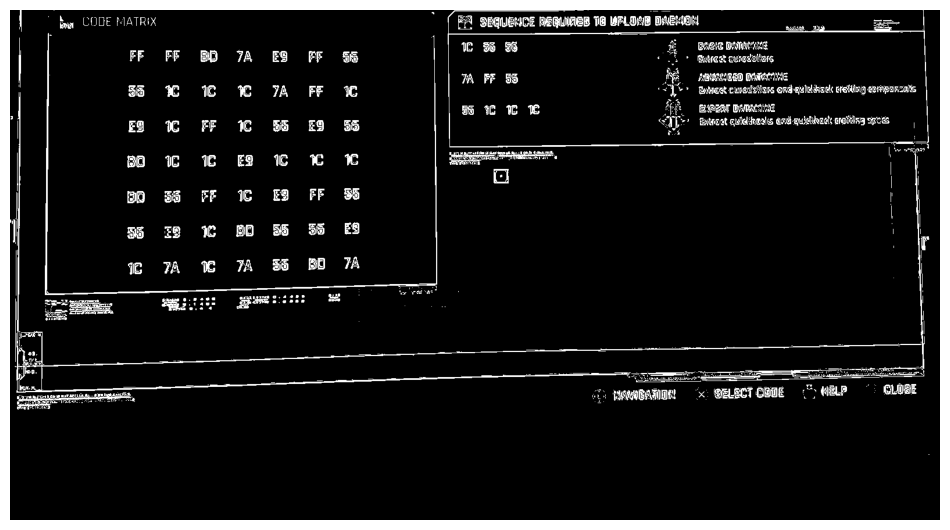

In [12]:
# Binarize the image using local median-difference thresholding
window = 9
threshold = 50
chosen_img = cropped

# Estimate the local background and identify significant pixel deviations
local_median = cv.medianBlur(chosen_img, window)
difference = cv.absdiff(chosen_img, local_median)
bool_img = difference > threshold

show_single_img(bool_img, cmap="gray")

### 1.4. Region Identification and Cropping

Use connected-component analysis to detect the resulting shapes and select the two components corresponding to the Code Matrix and Required Sequences, based on their dimensions. Crop these regions into separate images for subsequent processing.

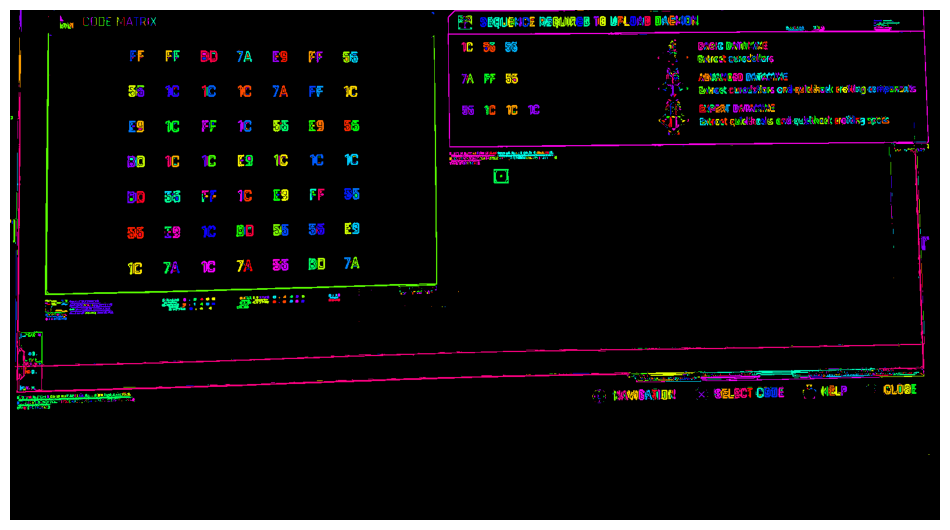

In [13]:
# Identify connected components in the binary image
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(bool_img.astype(np.uint8), connectivity=4)

# Assign distinct colors to components for visualization
rng = np.random.default_rng(42)
colors = plt.cm.hsv(rng.random(num_labels))
cmap = ListedColormap(colors)
cmap.set_bad("black")

# Hide the background and display the labeled components
labels_masked = np.ma.masked_where(labels == 0, labels)

show_single_img(labels_masked, cmap=cmap)

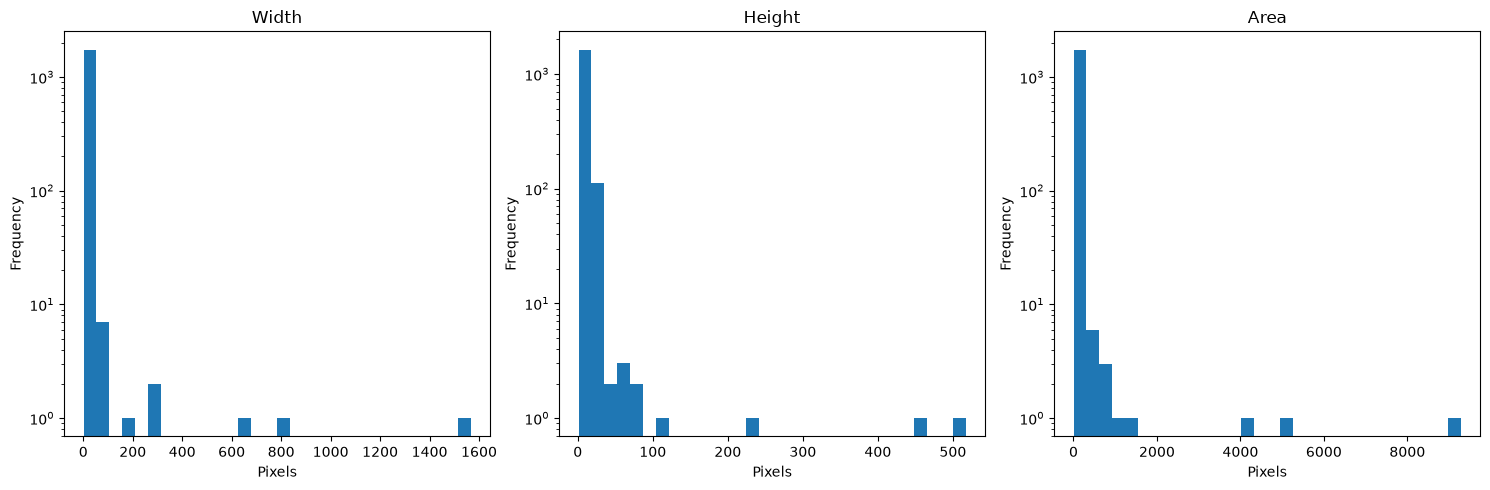

In [14]:
# Inspect the size distribution of connected components (excluding background)
attrs = {
    "Width": stats[1:, cv.CC_STAT_WIDTH],
    "Height": stats[1:, cv.CC_STAT_HEIGHT],
    "Area": stats[1:, cv.CC_STAT_AREA]
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, values) in zip(axes, attrs.items()):
    ax.hist(values, bins=30)
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Pixels")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Components retained: 2


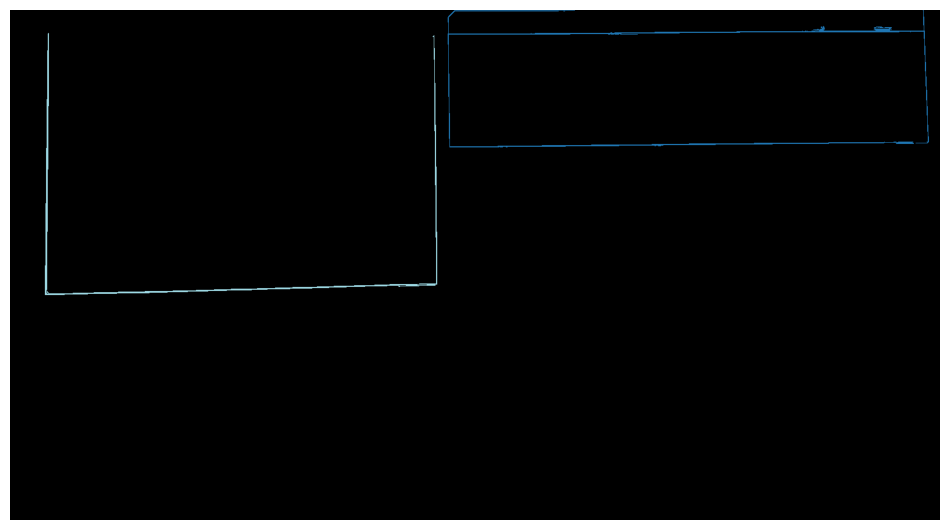

In [15]:
# Filter connected components by bounding-box dimensions
min_width, max_width = 500, 1000 # 500, 1000
min_height = 100 # 100

widths = stats[1:, cv.CC_STAT_WIDTH]
heights = stats[1:, cv.CC_STAT_HEIGHT]

valid_components = (
    (widths > min_width) &
    (widths < max_width) &
    (heights > min_height)
)

# Retrieve component IDs (excluding background label 0)
component_ids = np.flatnonzero(valid_components) + 1

# Mask background and excluded components
labels_masked = np.ma.masked_where(~np.isin(labels, component_ids),labels)

# Visualize retained components
cmap = plt.colormaps["tab20"].copy()
cmap.set_bad("black")

print(f"Components retained: {len(component_ids)}")
show_single_img(labels_masked, cmap=cmap)

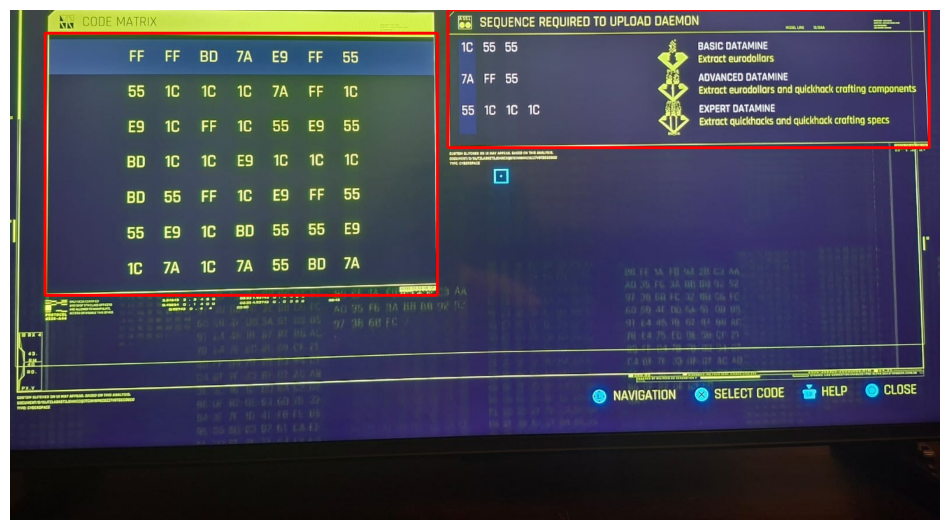

In [16]:
# Extract bounding boxes and visualize them on the original image
boxes = []
img_draw = img_rgb.copy()

for component_id in component_ids:
    left, top, width, height = stats[component_id, :4]

    top_left = (left, top)
    bottom_right = (left + width, top + height)

    boxes.append((left, top, left + width, top + height, height))

    cv.rectangle(img_draw, top_left, bottom_right, (255, 0, 0), 4)

boxes = np.array(boxes)

show_single_img(img_draw)

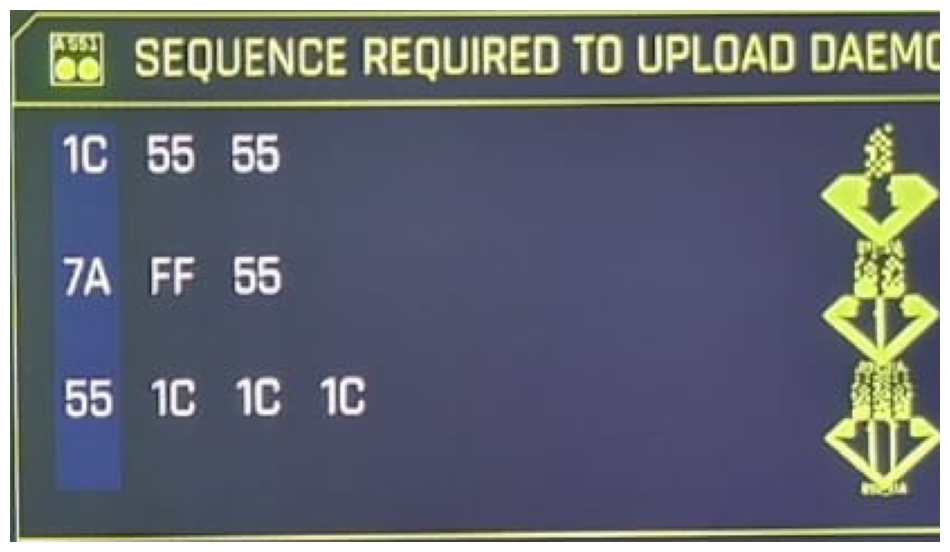

In [17]:
# Extract the sequences region from the original image
(left, top, right, bottom, width) = boxes[np.argmin(boxes[:, 4])]

sequences_img = img_rgb[top:bottom, left:right]

# Keep only the left half containing the target sequences
sequences_img = sequences_img[:, :sequences_img.shape[1] // 2]

show_single_img(sequences_img)

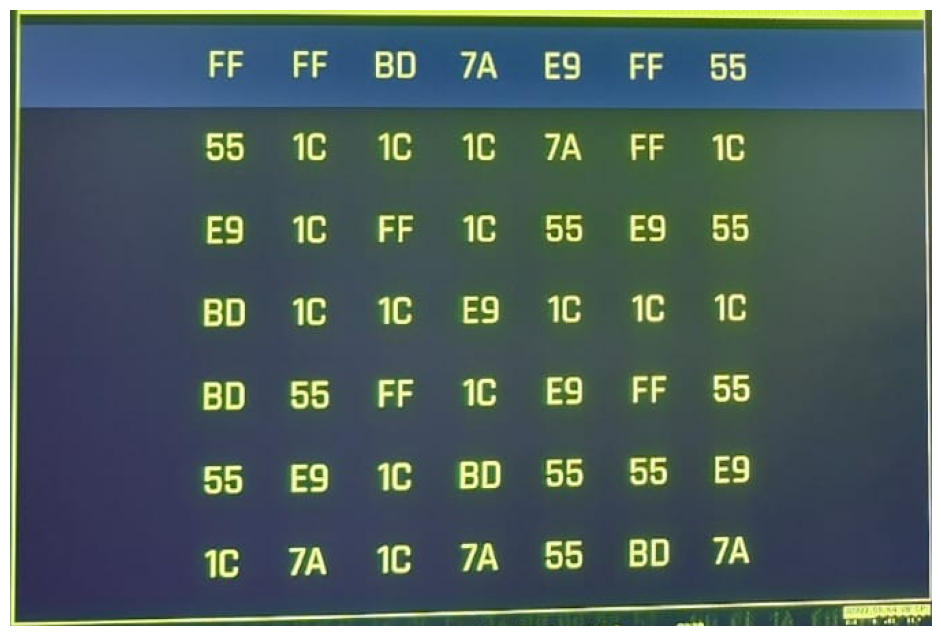

In [18]:
# Extract the main puzzle region from the original image
(left, top, right, bottom, width) = boxes[np.argmax(boxes[:, 4])]
matrix_img = img_rgb[top:bottom, left:right]

show_single_img(matrix_img)

## 2. Symbol Recognition

The objective of this stage is to convert the two cropped images into structured data: a two-dimensional array representing the *matrix* and *sequences*.

Both regions contain the same six possible hexadecimal symbols, allowing them to be classified using a common set of reference templates.

The recognition process follows these steps:

1. **Symbol Isolation:** Binarize each image using an appropriate color channel, then apply horizontal dilation to connect the pixels belonging to individual symbols. Connected-component analysis is used to identify and extract them.
2. **Symbol Normalization and Classification:** Normalize the extracted symbols to a standard size while preserving their proportions, then compare them against reference templates using Jaccard similarity to determine their identities.
3. **Spatial Reconstruction:** Use DBSCAN to group the recognized symbols according to their positions, reconstructing the *matrix* and *sequences* in their original arrangement.

Although both regions follow the same general process, they are handled separately to account for differences in their visual characteristics and spatial structure.

### 2.1. Classification Utilities

Before processing the symbols, two auxiliary functions are defined to standardize and classify them.

The first function normalizes binary images to a fixed size of 50 × 50 pixels, preserving their aspect ratio and centering the symbols within a uniform canvas. This ensures that extracted symbols can be compared consistently, regardless of their original dimensions.

The second function calculates the **Jaccard similarity** between each normalized symbol and the six reference templates. The template with the highest similarity score determines the predicted symbol.

In [19]:
def normalize_image(img: np.ndarray, size: tuple[int, int] = (50, 50)) -> np.ndarray:
    """
    Normalize a binary image while preserving its aspect ratio.

    Crops the image to its foreground bounding box, resizes it to
    fit within the target dimensions, and centers it on a black canvas.

    Args:
        img: Input image, with nonzero pixels treated as foreground.
        size: Target dimensions (width, height).

    Returns:
        Normalized binary image with values 0 and 1.
    """
    binary = (img > 0).astype(np.uint8)

    # Find the foreground bounding box
    y, x = np.nonzero(binary)

    if len(x) == 0:
        return np.zeros((size[1], size[0]), dtype=np.uint8)

    cropped = binary[y.min():y.max() + 1, x.min():x.max() + 1]

    # Resize while preserving the original aspect ratio
    h, w = cropped.shape
    target_w, target_h = size

    scale = min(target_w / w, target_h / h)
    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))

    resized = cv.resize(
        cropped,
        (new_w, new_h),
        interpolation=cv.INTER_NEAREST
    )

    # Center the resized image on a black canvas
    canvas = np.zeros((target_h, target_w), dtype=np.uint8)

    x_offset = (target_w - new_w) // 2
    y_offset = (target_h - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    return canvas

In [20]:
def similarity(img1: np.ndarray, img2: np.ndarray) -> float:
    """
    Calculate the Jaccard similarity between two binary images.

    Args:
        img1: First binary image.
        img2: Second binary image of the same shape.

    Returns:
        Jaccard similarity score between 0 and 1.
    """
    intersection = np.logical_and(img1, img2).sum()
    union = np.logical_or(img1, img2).sum()

    return intersection / union if union > 0 else 0.0


def classify(img: np.ndarray, templates: dict[str, np.ndarray]) -> tuple[str, dict[str, float]]:
    """
    Classify a binary image using Jaccard template matching.

    Args:
        img: Binary image to classify.
        templates: Dictionary mapping symbol labels to binary templates.

    Returns:
        Predicted symbol label and similarity scores for all templates.
    """
    scores = {
        label: similarity(img, template)
        for label, template in templates.items()
    }

    prediction = max(scores, key=scores.get)

    return prediction, scores

### 2.2. Code Matrix Recognition

The objective of this subsection is to identify the individual symbols within the *matrix* and reconstruct their original arrangement as a two-dimensional NumPy array.

#### 2.2.1. Symbol Isolation

The green channel is extracted and binarized to distinguish the bright symbols from the background.

Horizontal dilation is then applied to connect nearby pixels belonging to the same symbol, allowing connected-component analysis to identify them as individual regions.

Components are filtered according to their dimensions, and the surviving symbols are extracted using expanded bounding boxes applied to the original binary mask.

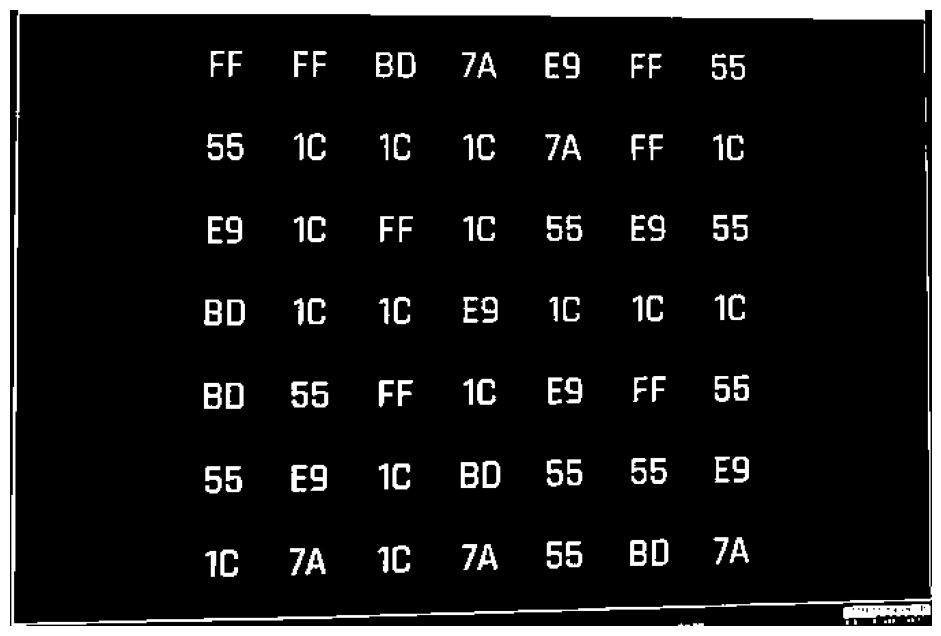

In [26]:
# Binarize the puzzle image using a fixed threshold on the green channel
threshold = 200
green_channel = matrix_img[:, :, 1]

matrix_mask = green_channel > threshold

show_single_img(matrix_mask, cmap="gray")

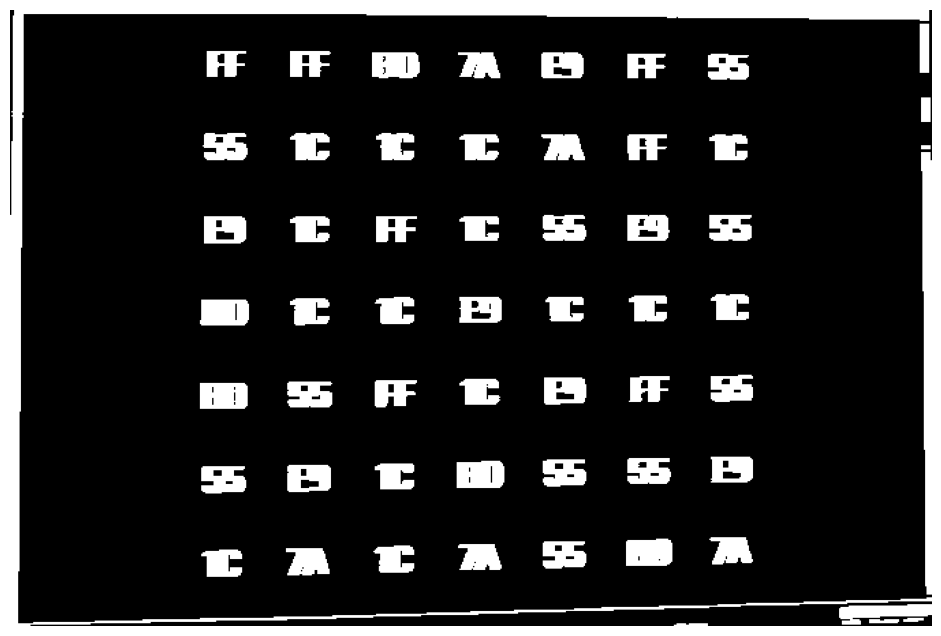

In [27]:
# Horizontally dilate the binary image to connect nearby symbol pixels
kernel = cv.getStructuringElement(cv.MORPH_RECT, (7, 1))
dilated_mask = cv.dilate(matrix_mask.astype(np.uint8), kernel, iterations=1)

show_single_img(dilated_mask, cmap="gray")

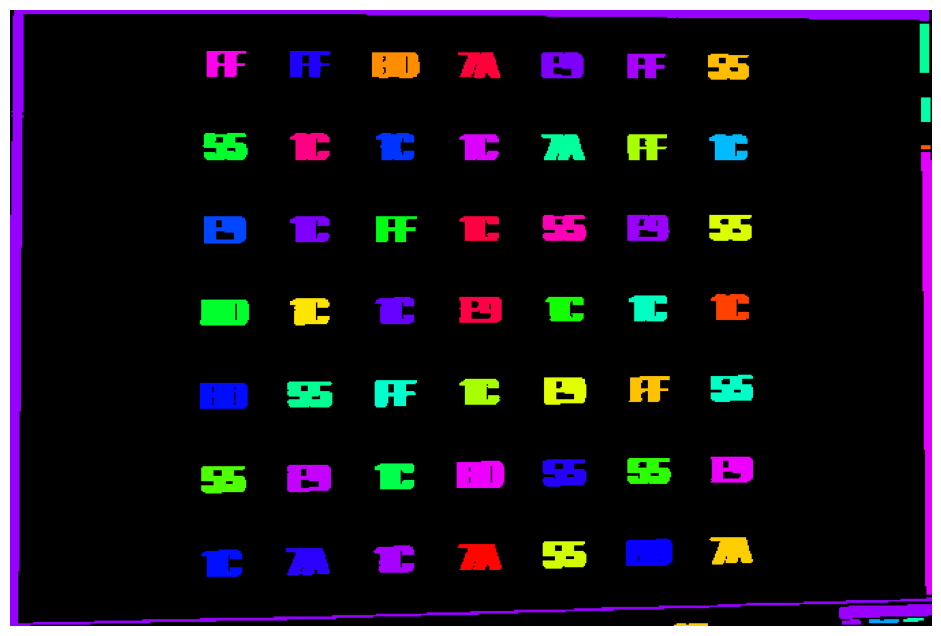

In [28]:
# Identify connected components in the dilated binary image
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(dilated_mask, connectivity=8)

# Assign distinct colors to components for visualization
rng = np.random.default_rng(42)
colors = plt.cm.hsv(rng.random(num_labels))
cmap = ListedColormap(colors)
cmap.set_bad("black")

# Hide the background and display the labeled components
labels_masked = np.ma.masked_where(labels == 0, labels)

show_single_img(labels_masked, cmap=cmap)

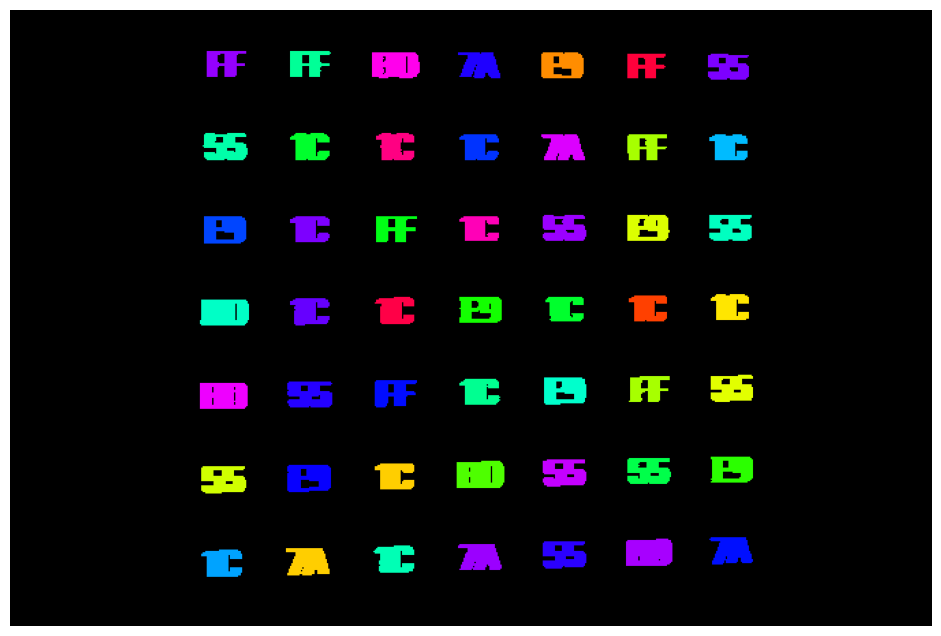

In [29]:
# Filter components based on their dimensions relative to the median
widths = stats[1:, cv.CC_STAT_WIDTH]
heights = stats[1:, cv.CC_STAT_HEIGHT]

median_width = np.median(widths)
median_height = np.median(heights)

tolerance = 0.2

# Retain components within tolerance of both median dimensions
width_mask = np.abs(widths / median_width - 1) < tolerance
height_mask = np.abs(heights / median_height - 1) < tolerance

valid_components = np.flatnonzero(width_mask & height_mask) + 1
filtered_stats = stats[valid_components]

# Mask background and excluded components
filtered_labels_masked = np.ma.masked_where(
    ~np.isin(labels, valid_components),
    labels
)

show_single_img(filtered_labels_masked, cmap=cmap)

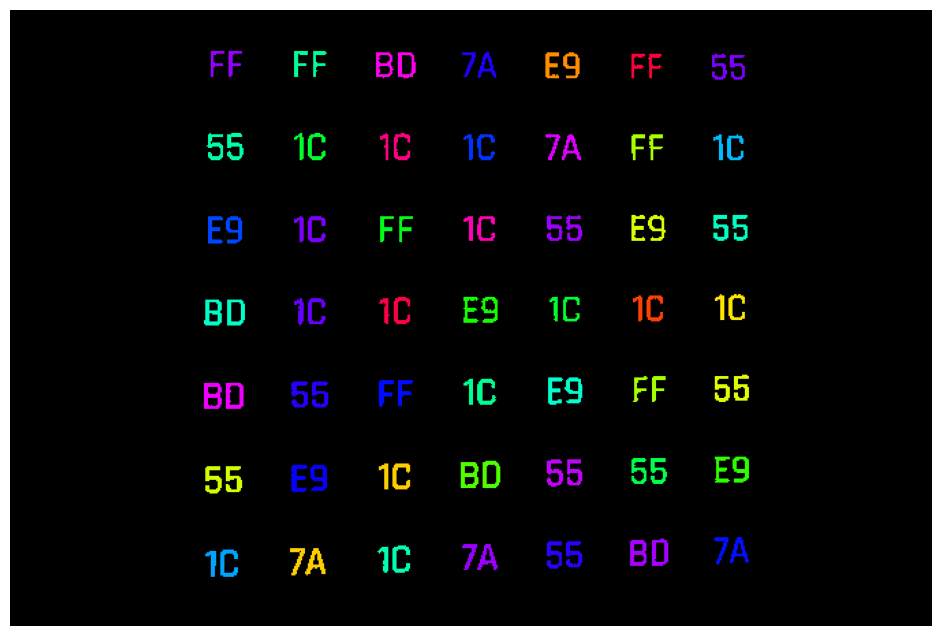

In [30]:
# Restore original symbol shapes while preserving component labels
restored_labels = np.where(matrix_mask, labels, 0)

# Mask background and excluded components
restored_labels_masked = np.ma.masked_where(
    ~np.isin(restored_labels, valid_components),
    restored_labels
)

show_single_img(restored_labels_masked, cmap=cmap)

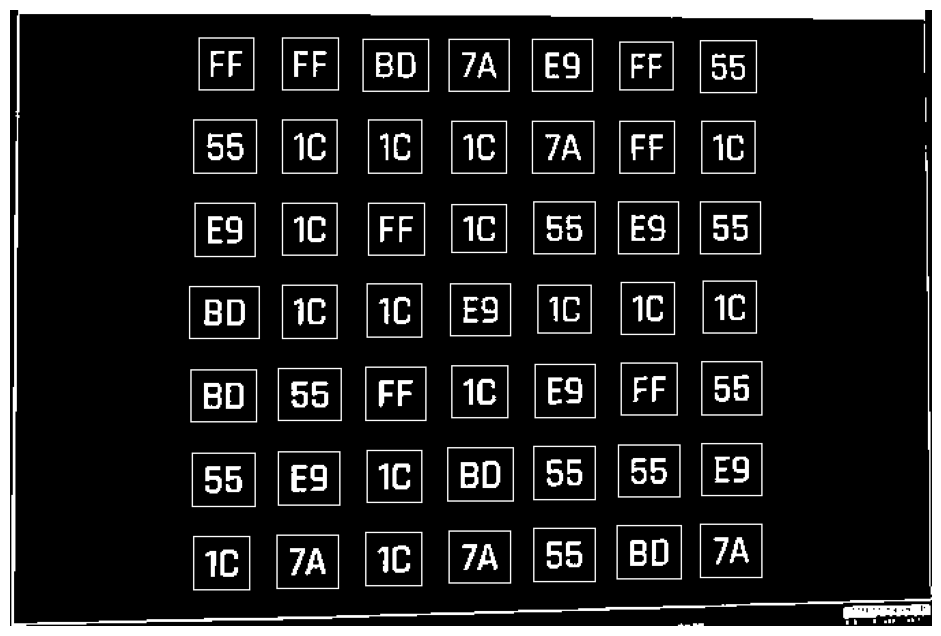

In [31]:
# Extract individual symbols using expanded bounding boxes
img_draw = matrix_mask.astype(np.uint8).copy()
imgs_cropped = []

height_img, width_img = matrix_mask.shape

for component_stats in filtered_stats:
    left, top, width, height = component_stats[:4]

    # Expand bounding boxes to capture complete symbols
    x1 = max(0, int(np.floor(left - width * 0.2)))
    y1 = max(0, int(np.floor(top - height * 0.5)))
    x2 = min(width_img, int(np.ceil(left + width * 1.2)))
    y2 = min(height_img, int(np.ceil(top + height * 1.5)))

    # Extract each symbol from the original binary mask
    img_cropped = matrix_mask[y1:y2, x1:x2]
    imgs_cropped.append(img_cropped)

    cv.rectangle(img_draw, (x1, y1), (x2 - 1, y2 - 1), 1, 1)

show_single_img(img_draw, cmap="gray")

#### 2.2.2. Symbol Classification

Each extracted symbol is normalized using the previously defined function and compared against the reference templates.

Jaccard similarity scores are calculated for all six possible symbols, and the template with the highest score is selected as the predicted classification.

An example is displayed to illustrate the transformation from the original cropped symbol to its normalized representation and corresponding template.

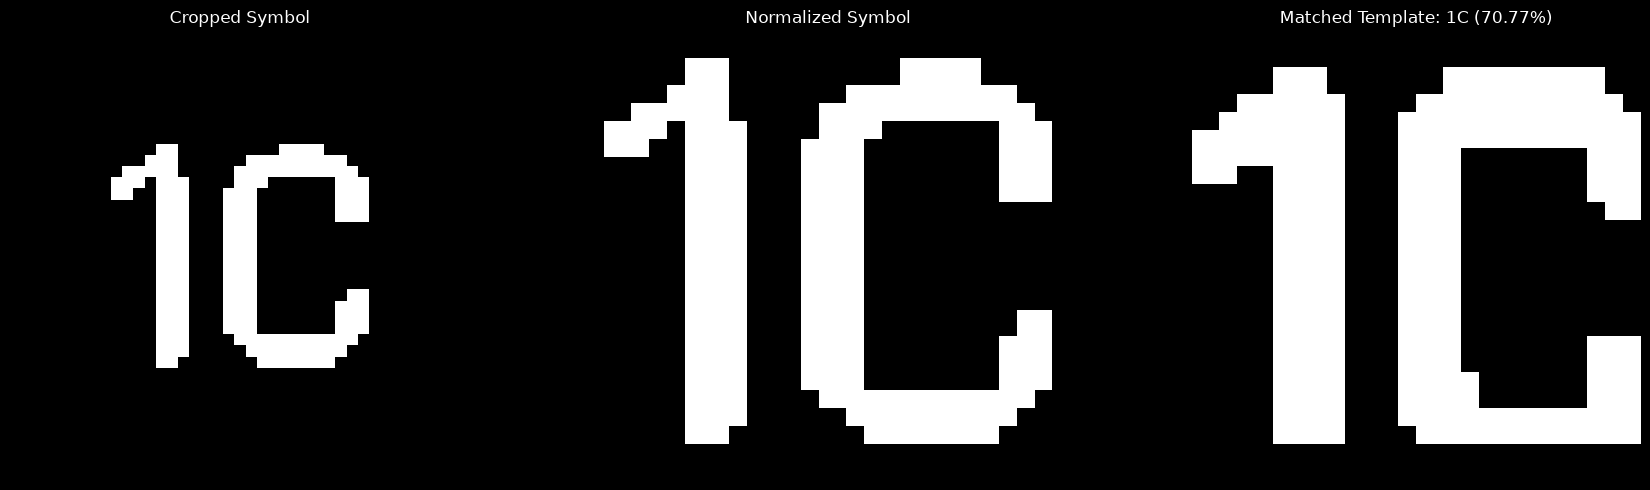

{'55': np.float64(0.2437619961612284), '1C': np.float64(0.7076502732240437), 'BD': np.float64(0.24816544362908605), 'E9': np.float64(0.28992944194996795), '7A': np.float64(0.24050632911392406), 'FF': np.float64(0.14255167498218105)}


In [32]:
# Normalize all extracted symbols
imgs_normalized = np.array([normalize_image(img) for img in imgs_cropped])

# Inspect an example of template-based symbol classification
symbol_idx = 8

cropped_img = imgs_cropped[symbol_idx]
normalized_img = imgs_normalized[symbol_idx]

prediction, scores = classify(normalized_img, templates)

# Compare the cropped symbol, normalized symbol, and best-matching template
images = [cropped_img, normalized_img, templates[prediction]]
titles = [
    "Cropped Symbol",
    "Normalized Symbol",
    f"Matched Template: {prediction} ({scores[prediction]:.2%})"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title, color='white')
    ax.axis("off")

fig.patch.set_facecolor("black")
plt.tight_layout()
plt.show()

# Display similarity scores
print(scores)

#### 2.2.3. Matrix Reconstruction

Once the symbols have been isolated, their original coordinates are used to reconstruct the *matrix*.

DBSCAN is applied independently to their horizontal and vertical positions to identify the rows and columns. The symbols are then ordered according to these spatial groupings and classified using the reference templates.

The result is a two-dimensional NumPy array representing the *matrix*.

In [33]:
# Group symbols into rows and columns
cols = filtered_stats[:, 0]
rows = filtered_stats[:, 1]

dbscan = DBSCAN(eps=10, min_samples=2)

row_labels = dbscan.fit_predict(rows.reshape(-1, 1))
col_labels = dbscan.fit_predict(cols.reshape(-1, 1))

if -1 in row_labels or -1 in col_labels:
    raise ValueError("Unclustered symbols detected.")

def order_labels(labels: np.ndarray, positions: np.ndarray) -> np.ndarray:
    """
    Reassign cluster labels according to their spatial positions.

    Args:
        labels: Cluster labels assigned to each element.
        positions: Spatial coordinate of each element.

    Returns:
        Array of sequential cluster labels ordered by mean position.
    """
    unique_labels = np.unique(labels)

    means = {
        label: positions[labels == label].mean()
        for label in unique_labels
    }

    ordered_labels = sorted(unique_labels, key=means.get)
    mapping = {label: i for i, label in enumerate(ordered_labels)}

    return np.array([mapping[label] for label in labels])

# Order clusters by their spatial positions
row_labels = order_labels(row_labels, rows)
col_labels = order_labels(col_labels, cols)

# Sort symbols from top to bottom, left to right
sort_idx = np.lexsort((col_labels, row_labels))

imgs_normalized = imgs_normalized[sort_idx]
row_labels = row_labels[sort_idx]

In [34]:
# Reconstruct the puzzle grid from classified symbols
rows = []
for row_label in np.unique(row_labels):
    row = [classify(imgs_normalized[i], templates)[0] for i in np.where(row_labels == row_label)[0]]
    rows.append(row)

matrix_array = np.array(rows)
matrix_array

array([['FF', 'FF', 'BD', '7A', 'E9', 'FF', '55'],
       ['55', '1C', '1C', '1C', '7A', 'FF', '1C'],
       ['E9', '1C', 'FF', '1C', '55', 'E9', '55'],
       ['BD', '1C', '1C', 'E9', '1C', '1C', '1C'],
       ['BD', '55', 'FF', '1C', 'E9', 'FF', '55'],
       ['55', 'E9', '1C', 'BD', '55', '55', 'E9'],
       ['1C', '7A', '1C', '7A', '55', 'BD', '7A']], dtype='<U2')

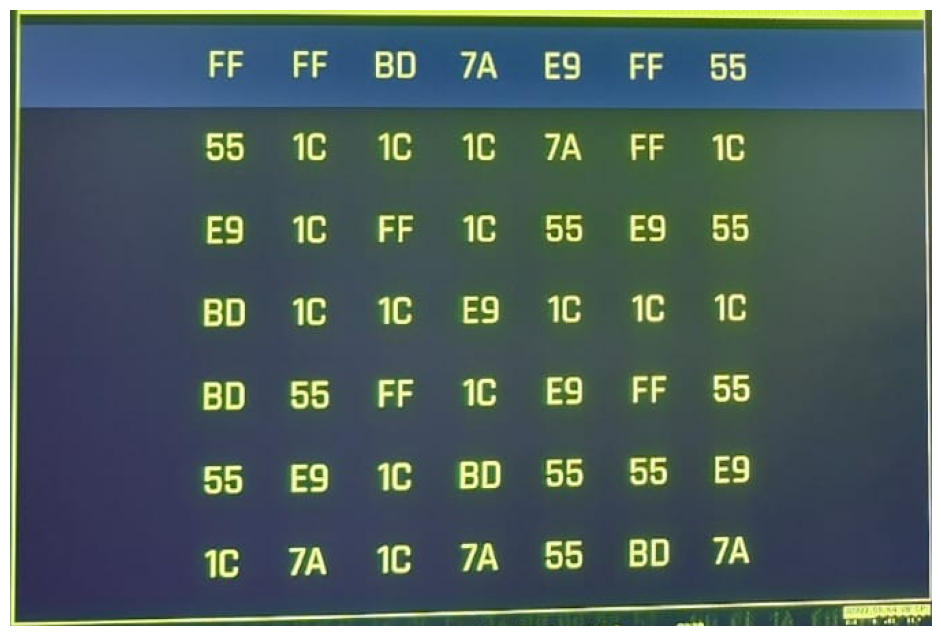

In [35]:
show_single_img(matrix_img)

### 2.3. Required Sequences Recognition

The same general recognition process is applied to the *sequences* region, with adjustments to account for differences in color and spatial arrangement.

The objective is to extract each target sequence as an ordered list of hexadecimal symbols.

#### 2.3.1. Symbol Isolation

Unlike the *matrix*, the *sequences* are binarized using the blue channel, which provides better contrast between the symbols and their background.

Horizontal dilation and connected-component analysis are then applied to identify individual symbols. Components are filtered based on their dimensions relative to the median, allowing similarly sized regions to be retained.

Finally, expanded bounding boxes are used to extract each symbol from the original binary mask.

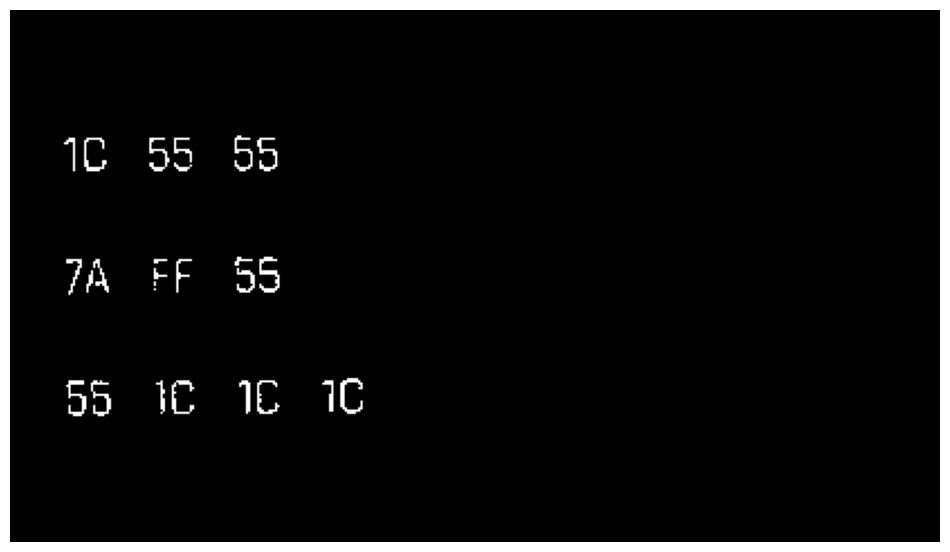

In [36]:
# Binarize the sequences image using a fixed threshold on the blue channel
test = sequences_img[:, :, 2]

sequences_mask = test > 240
show_single_img(sequences_mask, cmap='gray')

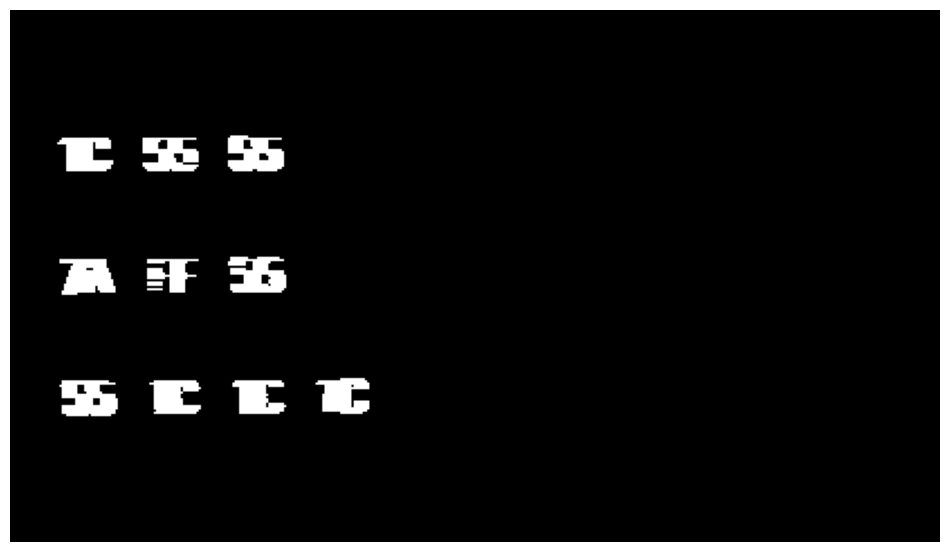

In [37]:
# Horizontally dilate the binary image to connect nearby symbol pixels

kernel = cv.getStructuringElement(cv.MORPH_RECT, (7, 1))
dilated_mask = cv.dilate(sequences_mask.astype(np.uint8), kernel, iterations=1)

show_single_img(dilated_mask, cmap='gray')

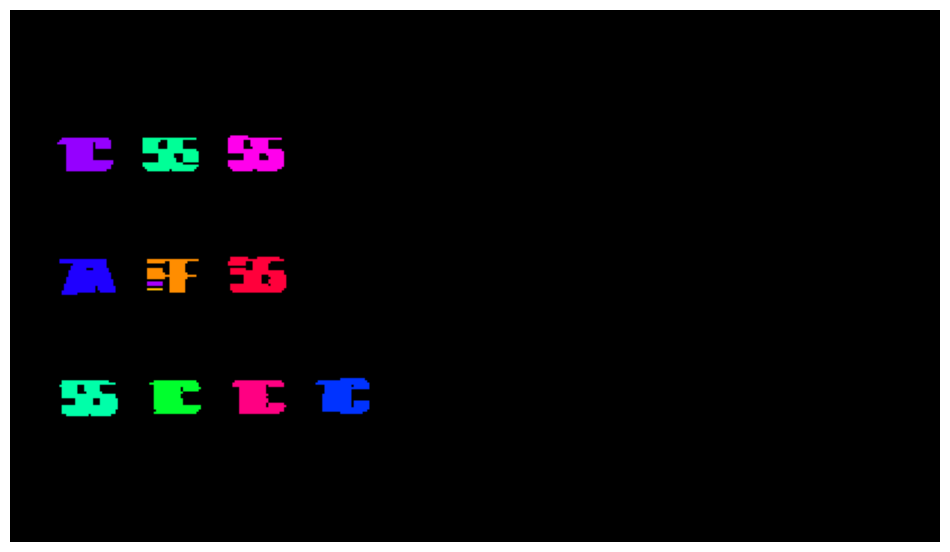

In [38]:
# Identify connected components in the dilated binary image
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(dilated_mask, connectivity=8)

# Assign distinct colors to components for visualization
rng = np.random.default_rng(42)
colors = plt.cm.hsv(rng.random(num_labels))
cmap = ListedColormap(colors)
cmap.set_bad("black")

# Hide the background and display the labeled components
labels_masked = np.ma.masked_where(labels == 0, labels)

show_single_img(labels_masked, cmap=cmap)

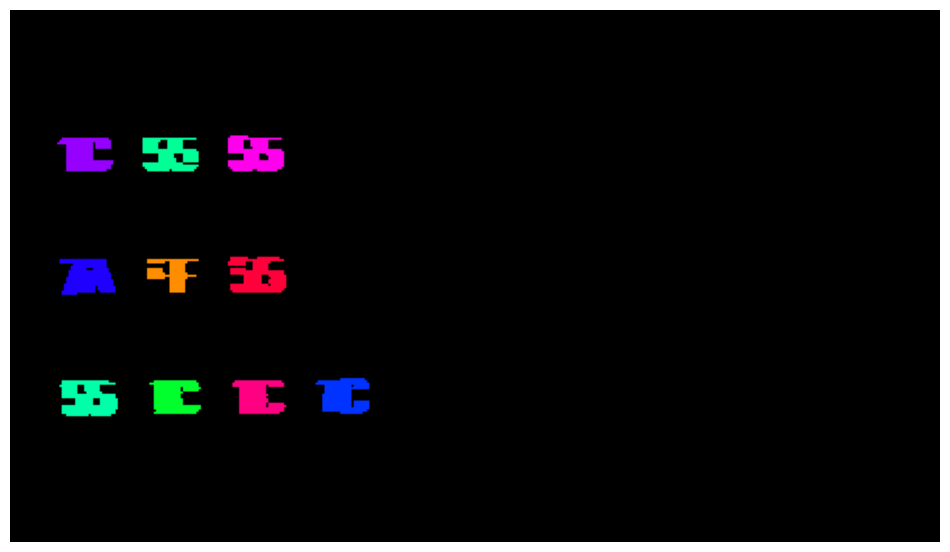

In [39]:
# Filter components based on their dimensions relative to the median
widths = stats[1:, cv.CC_STAT_WIDTH]
heights = stats[1:, cv.CC_STAT_HEIGHT]

median_width = np.median(widths)
median_height = np.median(heights)

tolerance = 0.2

# Retain components within tolerance of both median dimensions
width_mask = np.abs(widths / median_width - 1) < tolerance
height_mask = np.abs(heights / median_height - 1) < tolerance

valid_components = np.flatnonzero(width_mask & height_mask) + 1
filtered_stats = stats[valid_components]

# Mask background and excluded components
filtered_labels_masked = np.ma.masked_where(
    ~np.isin(labels, valid_components),
    labels
)

show_single_img(filtered_labels_masked, cmap=cmap)

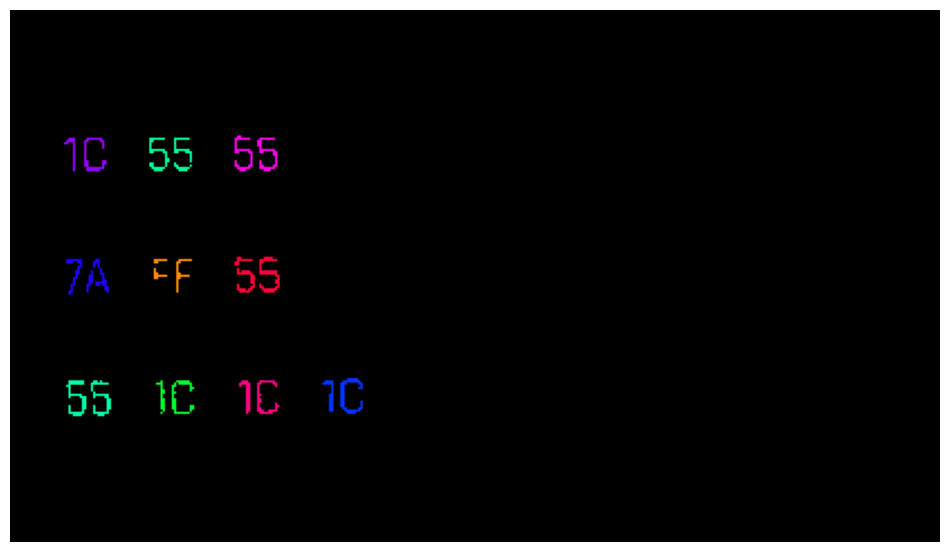

In [40]:
# Restore original symbol shapes while preserving component labels
restored_labels = np.where(sequences_mask, labels, 0)

# Mask background and excluded components
restored_labels_masked = np.ma.masked_where(
    ~np.isin(restored_labels, valid_components),
    restored_labels
)

show_single_img(restored_labels_masked, cmap=cmap)

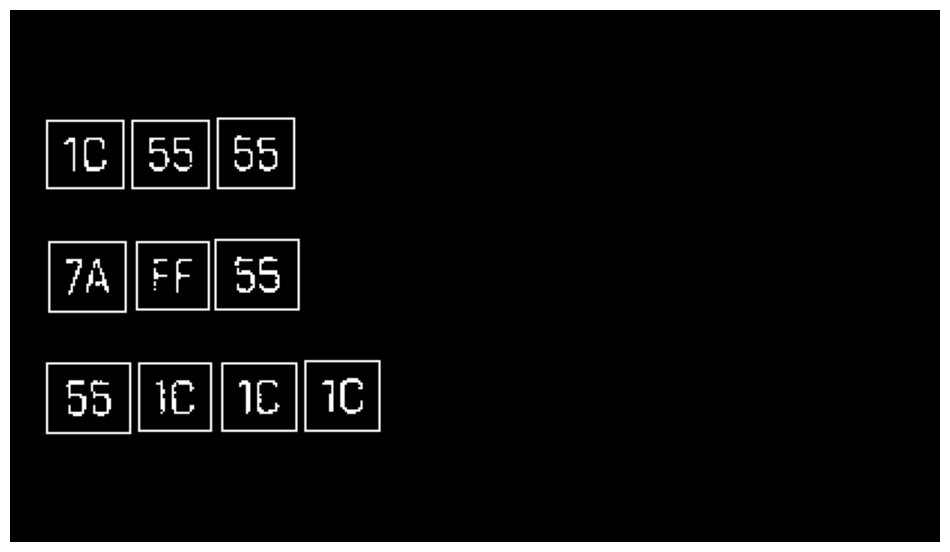

In [41]:
# Extract individual symbols using expanded bounding boxes
img_draw = sequences_mask.astype(np.uint8).copy()
imgs_cropped = []

height_img, width_img = sequences_mask.shape

for component_stats in filtered_stats:
    left, top, width, height = component_stats[:4]

    # Expand bounding boxes to capture complete symbols
    x1 = max(0, int(np.floor(left - width * 0.2)))
    y1 = max(0, int(np.floor(top - height * 0.5)))
    x2 = min(width_img, int(np.ceil(left + width * 1.2)))
    y2 = min(height_img, int(np.ceil(top + height * 1.5)))

    # Extract each symbol from the original binary mask
    img_cropped = sequences_mask[y1:y2, x1:x2]
    imgs_cropped.append(img_cropped)

    cv.rectangle(img_draw, (x1, y1), (x2 - 1, y2 - 1), 1, 1)

show_single_img(img_draw, cmap="gray")

#### 2.3.2. Symbol Classification

The extracted symbols are normalized and classified using the same functions and reference templates defined previously.

As with the Code Matrix, an example is displayed to compare the cropped symbol, its normalized representation, and the best-matching template, along with the corresponding similarity scores.

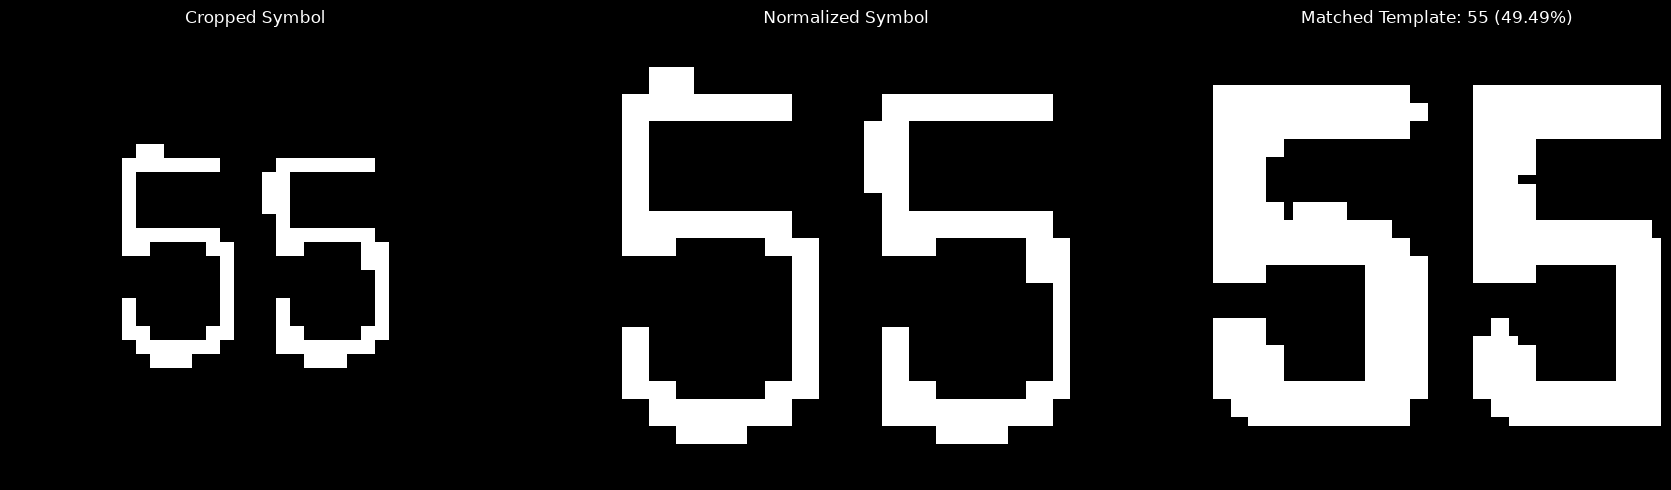

{'55': np.float64(0.49485420240137223), '1C': np.float64(0.22637362637362637), 'BD': np.float64(0.36437908496732024), 'E9': np.float64(0.38910207214121256), '7A': np.float64(0.19586840091813312), 'FF': np.float64(0.30297397769516726)}


In [42]:
# Normalize all extracted symbols
imgs_normalized = np.array([normalize_image(img) for img in imgs_cropped])

# Inspect an example of template-based symbol classification
symbol_idx = 2

cropped_img = imgs_cropped[symbol_idx]
normalized_img = imgs_normalized[symbol_idx]

prediction, scores = classify(normalized_img, templates)

# Compare the cropped symbol, normalized symbol, and best-matching template
images = [cropped_img, normalized_img, templates[prediction]]
titles = [
    "Cropped Symbol",
    "Normalized Symbol",
    f"Matched Template: {prediction} ({scores[prediction]:.2%})"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title, color='white')
    ax.axis("off")

fig.patch.set_facecolor("black")
plt.tight_layout()
plt.show()

# Display similarity scores
print(scores)

#### 2.3.3. Sequence Reconstruction

To reconstruct the *sequences*, DBSCAN is applied to the vertical positions of the extracted symbols, grouping those belonging to the same sequence.

The symbols within each group are then classified and assembled into ordered lists.

The result is a list of target sequences, which will serve as the input for the subsequent optimization stage.

In [44]:
# Group symbols into rows based on their spatial positions
tops = filtered_stats[:, 1]

dbscan = DBSCAN(eps=10, min_samples=2)
labels = dbscan.fit_predict(tops.reshape(-1, 1))

if -1 in labels:
    raise ValueError("Unclustered symbols detected.")

# Order sequences from top to bottom
labels = order_labels(labels, tops)

In [45]:
# Reconstruct target sequences from classified symbols
lefts = filtered_stats[:, 0]

sequences = []

for label in np.unique(labels):
    indices = np.where(labels == label)[0]
    indices = indices[np.argsort(lefts[indices])]

    sequences.append([
        classify(imgs_normalized[i], templates)[0]
        for i in indices
    ])

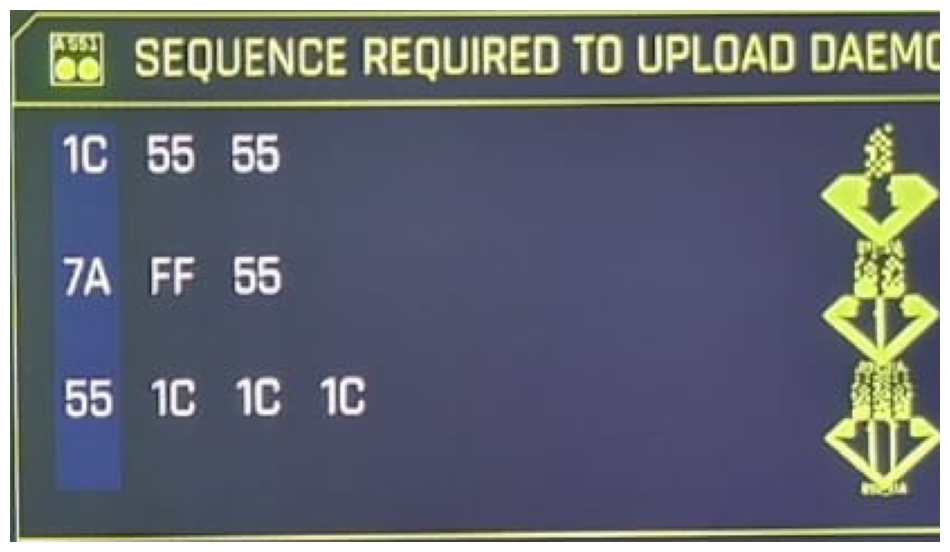

In [46]:
show_single_img(sequences_img)

## 3. Sequence Optimization

The objective of this stage is to identify combinations of target sequences that maximize the total reward while respecting the available buffer capacity.

Since multiple target sequences can share common symbols, they can potentially be combined into a single, shorter sequence. By exploiting these overlaps, it may be possible to complete more targets without increasing the number of required buffer slots.

The optimization process consists of three steps:

1. **Overlap Detection:** Identify shared symbols between the end of one sequence and the beginning of another.
2. **Sequence Merging:** Combine target sequences while avoiding the duplication of overlapping symbols.
3. **Combination Evaluation:** Generate possible combinations, discard those exceeding the buffer capacity, and prioritize the remaining candidates according to their total value.

The resulting candidates are passed to the pathfinding algorithm, which determines whether they can be constructed within the Code Matrix.

### 3.1. Overlap Detection

To identify opportunities for combining target sequences, a function is defined to calculate the longest matching overlap between two sequences.

The function compares the suffix of the first sequence against the prefix of the second, starting with the maximum possible overlap length and progressively decreasing it until a match is found.

The result is the number of symbols shared between the two sequences, which can be used to reduce the length of their combination.

In [47]:
def overlap(a: list[str], b: list[str]) -> int:
    """
    Return the length of the longest matching suffix of a and prefix of b.

    Args:
        a: First sequence.
        b: Second sequence.

    Returns:
        Number of overlapping elements.
    """
    for n in range(min(len(a), len(b)), 0, -1):
        if a[-n:] == b[:n]:
            return n
    return 0

### 3.2. Sequence Merging

Using the overlap length calculated previously, a second function combines two sequences without duplicating their shared symbols.

The first sequence is preserved, while only the non-overlapping portion of the second sequence is appended.

This operation allows multiple target sequences to be represented by a shorter combined sequence, potentially reducing the buffer capacity required to complete them.

In [48]:
def merge_overlap(a: list[str], b: list[str]) -> list[str]:
    """
    Merge two sequences while avoiding duplicate overlapping elements.

    Handles both suffix-prefix overlaps and cases where one sequence
    is entirely contained within the other.

    Args:
        a: First sequence.
        b: Second sequence.

    Returns:
        Shortest merged sequence found by containment or suffix-prefix overlap.
    """
    # Check whether b is already contained in a
    if any(a[i:i+len(b)] == b for i in range(len(a) - len(b) + 1)):
        return a.copy()

    # Check whether a is already contained in b
    if any(b[i:i+len(a)] == a for i in range(len(b) - len(a) + 1)):
        return b.copy()

    # Otherwise, merge using the longest suffix-prefix overlap
    n = overlap(a, b)
    return a + b[n:]

### 3.3. Combination Generation and Prioritization

To identify the most valuable combinations, permutations of the target sequences are evaluated, considering different numbers of targets and their possible execution orders.

For each permutation, the sequences are progressively merged using the previously defined overlap functions. Combinations exceeding the available buffer capacity are discarded.

**For prioritization, it is assumed that sequences appearing lower in the *sequences* list are more valuable, with their assigned value increasing linearly according to their position.** Thus, the first sequence receives a value of 1, the second a value of 2, and so on.

Each valid combination is assigned a total value equal to the sum of the values of its constituent target sequences. The remaining combinations are then sorted in descending order of value, prioritizing those that offer the greatest potential reward.

The result is an ordered list of candidate sequences, which will be evaluated during the pathfinding stage.

In [56]:
def sequence_value(
    combination: list[str],
    sequences: list[list[str]]
) -> int:
    """
    Calculate the total value of all target sequences contained
    within a candidate combination.

    Args:
        combination: Merged sequence to evaluate.
        sequences: Original target sequences, ordered by increasing value.

    Returns:
        Sum of the values of all satisfied target sequences.
    """
    value = 0

    # Check every original target sequence
    for i, seq in enumerate(sequences, start=1):
        if any(combination[j:j+len(seq)] == seq for j in range(len(combination) - len(seq) + 1)):
            value += i

    return value

def get_valid_combinations(
    sequences: list[list[str]],
    buffer: int,
    return_values: bool = False
) -> list[list[str]] | list[tuple[list[str], int]]:
    """
    Generate valid merged sequences, prioritized by total value.

    Evaluates permutations of the target sequences, merges overlapping
    elements, and retains combinations that fit within the buffer.
    Rewards are calculated based on all satisfied target sequences.

    Args:
        sequences: Target symbol sequences, ordered by increasing value.
        buffer: Maximum number of symbols allowed in a merged sequence.
        return_values: Whether to include the total value of each combination.

    Returns:
        Unique valid merged sequences sorted by descending value,
        optionally accompanied by their corresponding values.
    """
    valid_combinations = {}

    # Evaluate permutations of decreasing lengths
    for n in range(len(sequences)):
        for p in permutations(sequences, len(sequences) - n):

            # Merge sequences using their longest matching overlaps
            combination = list(p[0])
            for seq in p[1:]:
                combination = merge_overlap(combination, seq)

            if len(combination) <= buffer:

                # Calculate rewards from all satisfied targets
                value = sequence_value(combination, sequences)

                # Store unique combinations
                valid_combinations[tuple(combination)] = value

    # Prioritize by value, then by shortest sequence
    valid_combinations = sorted(valid_combinations.items(), key=lambda x: (-x[1], len(x[0])))

    if return_values:
        return [(list(c), v) for c, v in valid_combinations]

    return [list(c) for c, v in valid_combinations]

# Generate valid target sequences within the available buffer
buffer_size = 4

valid_sequences = get_valid_combinations(sequences, buffer_size)
valid_sequences

[['55', '1C', '1C', '1C'], ['7A', 'FF', '55'], ['1C', '55', '55']]

## 4. Pathfinding

The objective of this stage is to find a valid path through the Code Matrix that constructs one of the candidate sequences generated during optimization.

Unlike the previous stage, pathfinding must account for the movement constraints of Breach Protocol: selections must begin in the first row, alternate between horizontal and vertical movement, and cannot revisit previously selected cells. Additionally, the total number of selections cannot exceed the available buffer capacity.

A recursive **Depth-First Search (DFS)** algorithm with backtracking is used to explore possible paths. Candidate sequences are evaluated in descending order of value, allowing the solver to prioritize the most rewarding feasible solution.

### 4.1. Recursive Depth-First Search

The `explore()` function implements a recursive DFS algorithm to identify a valid path through the Code Matrix.

Starting from the first row, the algorithm explores available cells, alternating between horizontal and vertical movement after each selection. Each visited cell contributes its symbol to the constructed sequence and its coordinates to the current path.

At every recursive call, the algorithm checks whether the constructed sequence **ends with the target sequence**. This is intentional, as a valid solution may require additional symbols before the target can be completed. For example, a constructed sequence of `[1, 2, 3, 4]` successfully satisfies the target `[2, 3, 4]`. This behavior allows the algorithm to accommodate intermediate selections required to navigate the matrix without invalidating the target sequence.

If a match is found, the search terminates successfully.

If the buffer capacity is reached without finding a match, or a path cannot be extended further, the algorithm backtracks by removing the most recent selection and restoring the corresponding cell. This process continues until a valid path is found or all possible paths have been explored.

In [57]:
# Explore valid paths using recursive dfs and backtracking
def explore(
    path: list[tuple[int, int]],
    built_seq: list[str],
    board: np.ndarray,
    is_row: int,
    d: int,
    obj_seq: list[str]
) -> tuple[bool, list[str], list[tuple[int, int]]]:
    """
    Search for a path that ends with the target sequence.

    Explores the puzzle grid recursively, alternating between rows
    and columns while preventing cells from being visited twice.

    Args:
        path: Coordinates of the cells visited so far.
        built_seq: Sequence of symbols collected along the path.
        board: Puzzle grid, modified in place during exploration.
        is_row: Direction of exploration (1 for column, -1 for row).
        d: Maximum number of cells allowed in the path.
        obj_seq: Target sequence to construct.

    Returns:
        Tuple containing whether a solution was found, the collected
        sequence, and the corresponding path coordinates.
    """
    # Check whether the target sequence has been constructed
    if built_seq[len(built_seq) - len(obj_seq):] == obj_seq:
        return True, built_seq, path

    # Stop exploring when the buffer limit is reached
    if len(path) >= d:
        return False, built_seq, path

    # Determine the current position
    if len(path) != 0:
        last_pos = path[-1]
        i = last_pos[0]
        j = last_pos[1]
    else:
        i = 0
        j = 0

    # Select the next row or column to explore
    if is_row == 1:
        array = board[:, j]
    if is_row == -1:
        array = board[i, :]

    for n, element in enumerate(array):
        if element == "XX":
            continue

        if is_row == 1:
            i = n
        if is_row == -1:
            j = n

        # Visit the cell and extend the current sequence
        board[i, j] = "XX"

        path.append((i, j))
        built_seq.append(element)

        # Recursively explore in the opposite direction
        found, built_seq, path = explore(path, built_seq, board, -is_row, d, obj_seq)

        if found:
            return True, built_seq, path

        # Backtrack by restoring the previous state
        built_seq.pop()
        last_pos = path.pop()
        board[i, j] = element

    return False, built_seq, path

### 4.2. Candidate Sequence Evaluation

The candidate sequences generated during optimization are evaluated in descending order of their assigned value.

For each candidate, the Code Matrix and pathfinding variables are reset, and the recursive search is executed using the available buffer capacity as the maximum path length.

The process stops when the first feasible sequence is found. Since candidates are evaluated in order of value, this approach prioritizes the highest-valued solution among the generated candidates that can be constructed within the matrix.

In [58]:
# Search candidate sequences in descending value order until a solution is found
is_row = -1
d = buffer_size
found = False

for valid_sequence in valid_sequences:
    board = matrix_array.copy()
    built_seq = []
    path = []

    found, built_seq, path = explore(path, built_seq, board, is_row, d, valid_sequence)

    if found:
        break

### 4.3. Solution Representation

Once a valid path has been identified, its coordinates are used to construct a numerical representation of the solution.

A new array with the same dimensions as the Code Matrix is initialized with placeholder values. Each selected cell is then labeled according to its position in the path, indicating the order in which the symbols should be selected.

This representation provides a compact overview of the solution and allows the selected coordinates to be inspected directly.

In [59]:
result_board = np.full(matrix_array.shape, '--')
for i, step in enumerate(path):
    result_board[step[0], step[1]] = f'0{i}'

result_board

array([['--', '--', '--', '--', '--', '--', '00'],
       ['--', '02', '--', '--', '--', '--', '01'],
       ['--', '03', '--', '--', '--', '--', '--'],
       ['--', '--', '--', '--', '--', '--', '--'],
       ['--', '--', '--', '--', '--', '--', '--'],
       ['--', '--', '--', '--', '--', '--', '--'],
       ['--', '--', '--', '--', '--', '--', '--']], dtype='<U2')

### 4.4. Solution Visualization

To provide a more intuitive representation, the original screenshot and reconstructed Code Matrix are displayed side by side.

The selected cells are highlighted and numbered according to their selection order, while a progressive color palette illustrates the direction of the path. The corresponding sequence of hexadecimal symbols and buffer usage are also displayed.

Together, these visualizations provide both a numerical and graphical representation of the solution.

In [60]:
def plot_solution(puzzle_array: np.ndarray, path: list[tuple[int, int]], ax=None) -> None:
    """
    Args:
        puzzle_array: Two-dimensional array containing the puzzle symbols.
        path: Ordered list of selected (row, column) coordinates.
        ax: Optional Matplotlib axis on which to draw the solution.
    """
    n_rows, n_cols = puzzle_array.shape

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))

    # Draw grid cells and their symbols
    for i in range(n_rows):
        for j in range(n_cols):
            ax.add_patch(Rectangle(
                (j, i), 1, 1,
                facecolor="#F0F0F0",
                edgecolor="white",
                linewidth=2
            ))

            ax.text(
                j + 0.5, i + 0.5,
                puzzle_array[i, j],
                ha="center", va="center",
                fontsize=14
            )

    # Highlight selected cells and their order
    for step, (i, j) in enumerate(path, start=1):
        ax.add_patch(Rectangle(
            (j, i), 1, 1,
            facecolor="#B7E4C7",
            edgecolor="#2D6A4F",
            linewidth=2
        ))

        ax.text(
            j + 0.5, i + 0.75,
            str(step),
            ha="center", va="center",
            fontsize=10, color="#2D6A4F"
        )

    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_aspect("equal")
    ax.axis("off")

Solution found!
Selected sequence: 55, 1C, 1C, 1C
Buffer used: 4/4


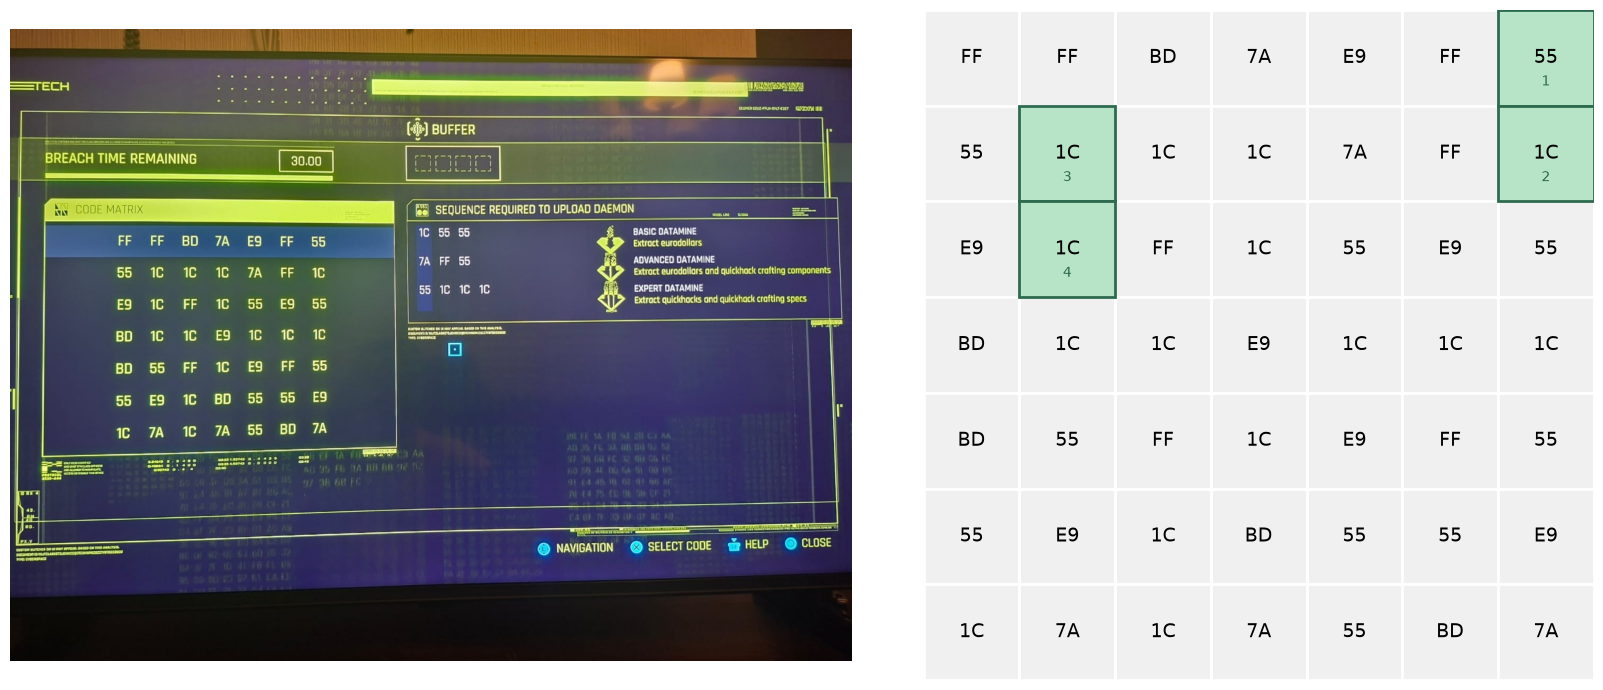

In [61]:
if found:
    print("Solution found!")
    print("Selected sequence:", ", ".join(built_seq))
    print(f"Buffer used: {len(path)}/{buffer_size}")

    fig, axes = plt.subplots(1, 2, figsize=(17, 7))

    # Original screenshot
    axes[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axes[0].axis("off")

    # Reconstructed matrix with solution
    plot_solution(matrix_array, path, ax=axes[1])

    plt.tight_layout()
    plt.show()

else:
    print("No valid solution found.")

## 5. Results and Limitations

The solver successfully processes the example image, reconstructs the Code Matrix and Required Sequences, and identifies a valid path within the specified buffer capacity.

The result demonstrates how image processing, template-based classification, sequence optimization, and recursive pathfinding can be combined into a single computational pipeline.

### 5.1. Limitations

Although the solver successfully handles the provided example, several limitations should be considered:

- **Image sensitivity:** The current implementation uses thresholds and component-size filters calibrated to the example image. Different resolutions, lighting conditions, or interface scaling may affect recognition accuracy.
- **Template dependence:** Symbol classification relies on predefined binary templates and may be sensitive to changes in font appearance or image quality.
- **Optimization scope:** The sequence-merging approach evaluates suffix-prefix overlaps and does not consider every possible arrangement of overlapping target sequences.
- **Computational complexity:** The number of potential paths increases rapidly with the size of the Code Matrix and available buffer, potentially increasing execution time.

### 5.2. Future Improvements

Potential improvements include more adaptive image segmentation, more robust spatial reconstruction, expanded sequence optimization, and pruning strategies to reduce the number of paths explored during DFS.

These improvements could make the solver more reliable across different screenshots and puzzle configurations.